# OpenCV Fundamentals — Hands-On Image Processing

A beginner-friendly, step-by-step Jupyter notebook covering essential OpenCV operations with practical examples.

This notebook is organized for the `learning-hub/OpenCV` repository. Each section introduces one concept and provides runnable Python code and visual output.

**Sample images:** `astronaut`, `camera`, `coffee`, and `chelsea` are included in the `images/` directory. If you have a properly licensed copy of the classic Lena image, you can place it in `images/lena.png` and substitute that path in the examples.

**How to use:** Run the cells in order. Results are displayed inline, and saved images appear in `outputs/`.

In [2]:
%pip install -q opencv-python numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


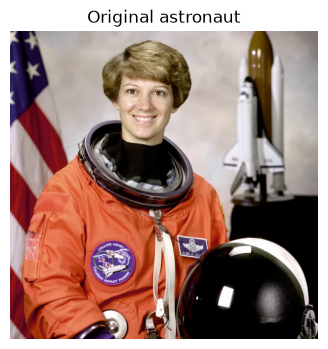

In [3]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

BASE = Path.cwd()
# Notebook can be run from inside OpenCV/ or a parent directory.
if not (BASE / "images" / "astronaut.png").exists() and (BASE / "OpenCV" / "images" / "astronaut.png").exists():
    BASE = BASE / "OpenCV"
IMG = BASE / "images"
OUT = BASE / "outputs"
OUT.mkdir(exist_ok=True)
def show(img, title="", cmap=None):
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(6, 4))
    plt.imshow(img, cmap=cmap, vmin=0 if cmap == "gray" else None, vmax=255 if cmap == "gray" else None)
    plt.title(title); plt.axis("off"); plt.show()
def pair(a, b, titles=("Original", "Result")):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, im, title in zip(axes, (a,b), titles):
        if im.ndim == 3: im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
        ax.set_title(title); ax.axis("off")
    plt.tight_layout(); plt.show()
img = cv2.imread(str(IMG / "astronaut.png"))
assert img is not None, "Run this notebook from the OpenCV folder."
show(img, "Original astronaut")

## 1. Read, Display, and Save Images — `imread`, `imshow`, `imwrite`

OpenCV loads images using `cv2.imread()` and saves them using `cv2.imwrite()`. In this notebook, Matplotlib displays images inline; `cv2.imshow()` opens a separate desktop window and may not work reliably in all notebook environments.

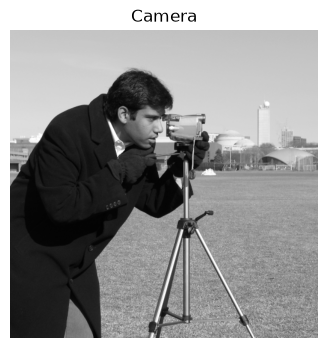

Saved: C:\Users\Surface Laptop\Downloads\OpenCV\outputs\camera_copy.png


In [4]:
camera = cv2.imread(str(IMG / "camera.png"), cv2.IMREAD_GRAYSCALE)
show(camera, "Camera", "gray")
cv2.imwrite(str(OUT / "camera_copy.png"), camera)
print("Saved:", OUT / "camera_copy.png")

## 2. Convert Between BGR, RGB, and Grayscale

OpenCV reads color images in BGR channel order, while Matplotlib expects RGB. Use `cv2.cvtColor()` to convert color spaces. A standard grayscale image has one intensity channel.

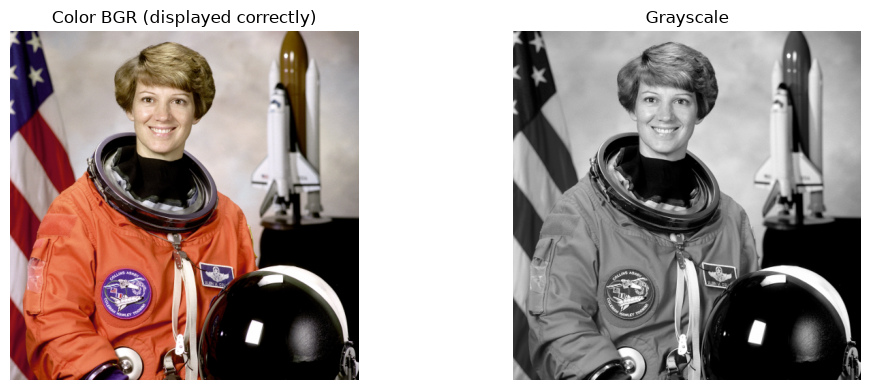

BGR: (512, 512, 3) | Gray: (512, 512)


In [5]:
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
pair(img, gray, ("Color BGR (displayed correctly)", "Grayscale"))
print("BGR:", img.shape, "| Gray:", gray.shape)

## 3. Crop an Image

NumPy slicing extracts a rectangular region. The indexing order is `[y1:y2, x1:x2]`, meaning rows first, then columns. The ending indices are excluded.

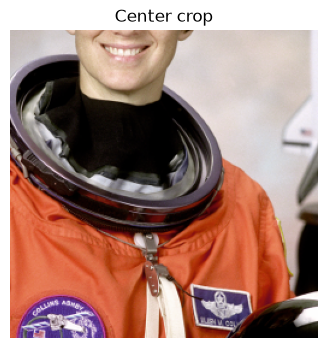

True

In [6]:
h, w = img.shape[:2]
crop = img[h//4:3*h//4, w//4:3*w//4]
show(crop, "Center crop")
cv2.imwrite(str(OUT / "crop.png"), crop)

## 4. Split and Merge Color Channels

Use `cv2.split()` to separate the Blue, Green, and Red channels and `cv2.merge()` to reconstruct the original BGR image.

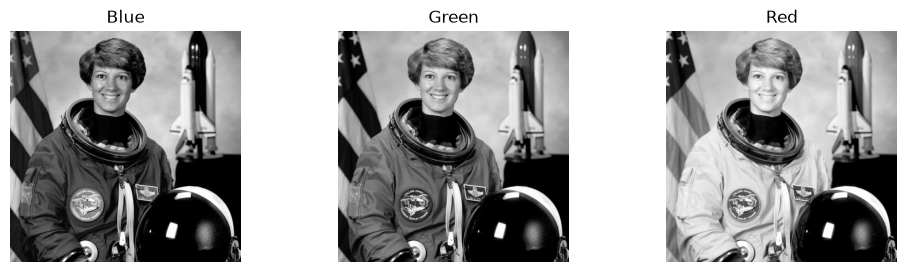

Merge reproduces original: True


In [7]:
b, g, r = cv2.split(img)
merged = cv2.merge([b, g, r])
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, channel, title in zip(axes, (b,g,r), ("Blue", "Green", "Red")):
    ax.imshow(channel, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.show()
print("Merge reproduces original:", np.array_equal(img, merged))

## 5. HSV Color Space and Red Color Detection

HSV represents hue, saturation, and value. For 8-bit images, OpenCV uses H in the range 0–179 and S/V in the range 0–255. Red wraps around the hue boundary, so we combine two hue ranges using a binary mask.

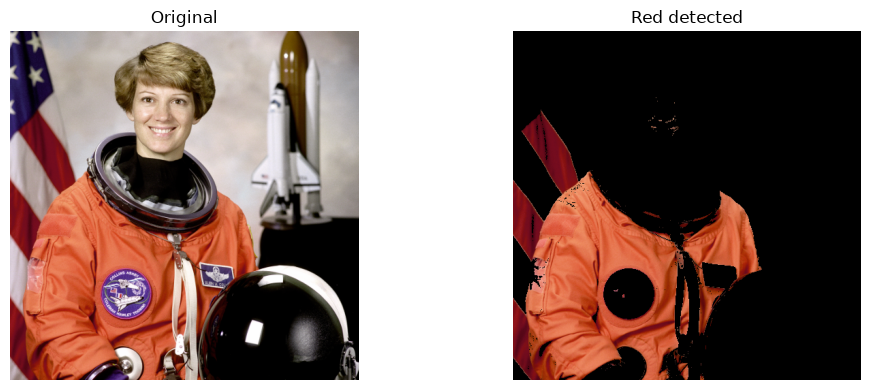

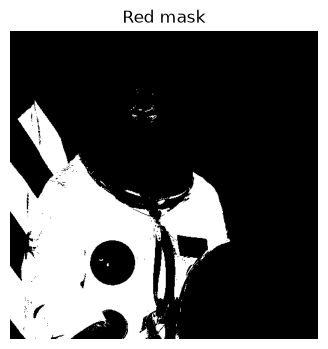

In [8]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
m1 = cv2.inRange(hsv, np.array([0,100,80]), np.array([10,255,255]))
m2 = cv2.inRange(hsv, np.array([170,100,80]), np.array([179,255,255]))
red_mask = cv2.bitwise_or(m1, m2)
red_only = cv2.bitwise_and(img, img, mask=red_mask)
pair(img, red_only, ("Original", "Red detected"))
show(red_mask, "Red mask", "gray")

## 6. Alpha Channels and Image Blending

An alpha channel describes opacity independently for each pixel. Here, we programmatically create a transparent dice graphic and blend it over a background image.

Convert 8-bit alpha values from 0–255 to 0–1. Multiply by 0.5 to make the dice 50% opaque, then apply `output = foreground * alpha + background * (1 - alpha)`.

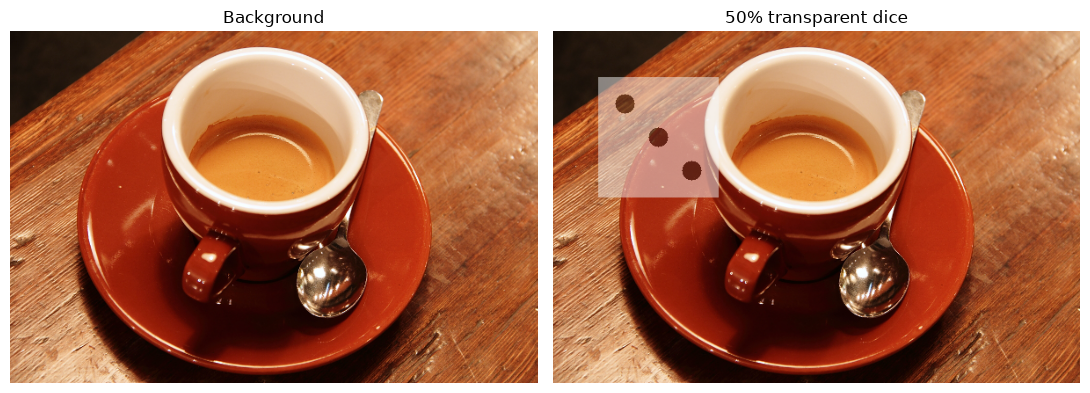

True

In [9]:
background = cv2.imread(str(IMG / "coffee.png"))
dice = np.zeros((160,160,4), dtype=np.uint8)
cv2.rectangle(dice, (12,12), (148,148), (245,245,245,255), -1)
for cx,cy in [(42,42),(80,80),(118,118)]:
    cv2.circle(dice,(cx,cy),11,(25,25,25,255),-1)
cv2.imwrite(str(OUT / "dice_transparent.png"), dice)
x,y = 40,40
dh,dw = dice.shape[:2]
roi = background[y:y+dh, x:x+dw].astype(np.float32)
alpha = (dice[:,:,3:4].astype(np.float32)/255.0)*0.5
fg = dice[:,:,:3].astype(np.float32)
blended = background.copy()
blended[y:y+dh,x:x+dw] = np.clip(fg*alpha+roi*(1-alpha),0,255).astype(np.uint8)
pair(background, blended, ("Background", "50% transparent dice"))
cv2.imwrite(str(OUT / "alpha_blending.png"), blended)

## 7. Binary Masks and Bitwise Operations — AND, OR, XOR, NOT

Create a circular mask and a rectangular mask. AND keeps their intersection, OR keeps their union, XOR keeps pixels belonging to exactly one mask, and NOT inverts a mask. Applying a mask to an image keeps selected pixels and sets the rest to black.

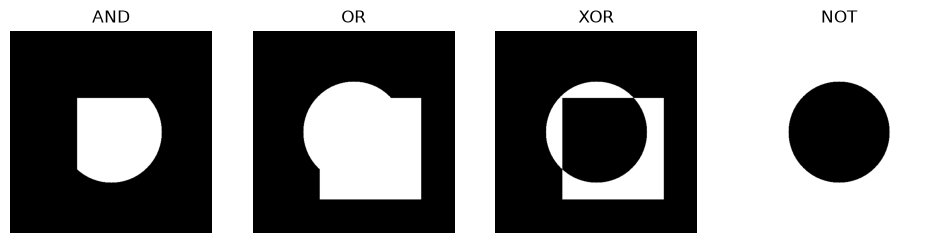

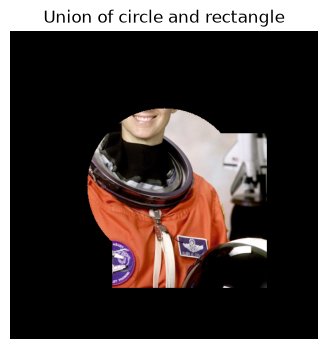

In [10]:
mask1 = np.zeros(img.shape[:2], np.uint8)
mask2 = np.zeros_like(mask1)
cv2.circle(mask1,(w//2,h//2),w//4,255,-1)
cv2.rectangle(mask2,(w//3,h//3),(5*w//6,5*h//6),255,-1)
m_and = cv2.bitwise_and(mask1,mask2)
m_or = cv2.bitwise_or(mask1,mask2)
m_xor = cv2.bitwise_xor(mask1,mask2)
m_not = cv2.bitwise_not(mask1)
fig,axes=plt.subplots(1,4,figsize=(12,3))
for ax,m,t in zip(axes,(m_and,m_or,m_xor,m_not),("AND","OR","XOR","NOT")):
    ax.imshow(m,cmap="gray",vmin=0,vmax=255); ax.set_title(t); ax.axis("off")
plt.show()
selected = cv2.bitwise_and(img,img,mask=m_or)
show(selected,"Union of circle and rectangle")

## 8. Draw Lines, Rectangles, Circles, and Ellipses

OpenCV drawing functions modify the supplied image. The ellipse parameters include center, semi-axis lengths, rotation angle, start/end angles, color, and thickness.

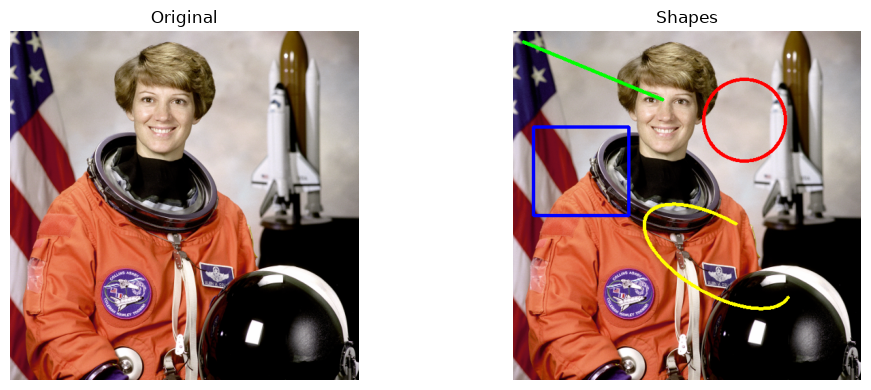

In [11]:
drawn = img.copy()
cv2.line(drawn,(15,15),(220,100),(0,255,0),3)
cv2.rectangle(drawn,(30,140),(170,270),(255,0,0),3)
cv2.circle(drawn,(340,130),60,(0,0,255),3)
cv2.ellipse(drawn,(300,330),(120,55),30,0,270,(0,255,255),3)
pair(img,drawn,("Original","Shapes"))

## 9. Add Text to an Image — `putText`

`cv2.putText()` places text at a specified baseline origin. You can control font, scale, BGR color, thickness, and line rendering. OpenCV's built-in Hershey fonts do not directly support most non-Latin scripts.

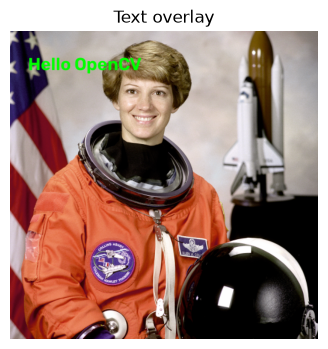

In [12]:
text_img=img.copy()
cv2.putText(text_img,"Hello OpenCV",(30,65),cv2.FONT_HERSHEY_SIMPLEX,1,(0,255,0),2,cv2.LINE_AA)
show(text_img,"Text overlay")

## 10. Image Arithmetic — Addition, Subtraction, Multiplication, and Division

Arithmetic operations work element by element. For 8-bit images, OpenCV typically saturates out-of-range results to 0–255. Division by zero yields 0 in this `uint8` example. Multiplication uses a scale factor here to avoid immediate saturation.

In [13]:
a = np.full((140,220),180,dtype=np.uint8)
b = np.full((140,220),100,dtype=np.uint8)
ops = {"add":cv2.add(a,b),"subtract":cv2.subtract(a,b),
       "multiply":cv2.multiply(a,b,scale=1/255),
       "divide":cv2.divide(a,b)}
for name, value in ops.items():
    print(name, ":", int(value[0,0]))
# Division by zero in uint8 produces 0 in cv2.divide.
print("division by zero:", int(cv2.divide(a,np.zeros_like(b))[0,0]))

add : 255
subtract : 80
multiply : 71
divide : 2
division by zero: 0


## 11. Grayscale and Color Histograms

A histogram counts how many pixels have each intensity value. Grayscale histograms describe overall intensity distribution; separate B, G, and R histograms describe each color channel. Histograms do not preserve pixel positions.

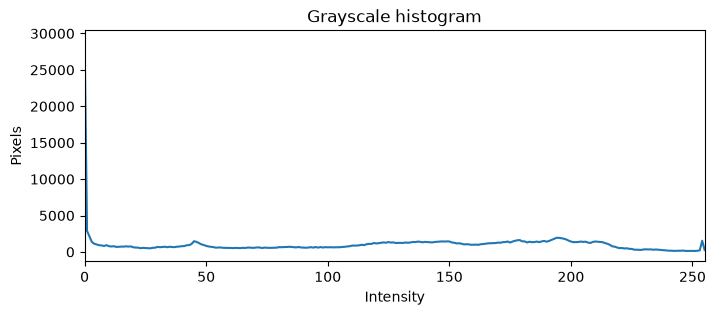

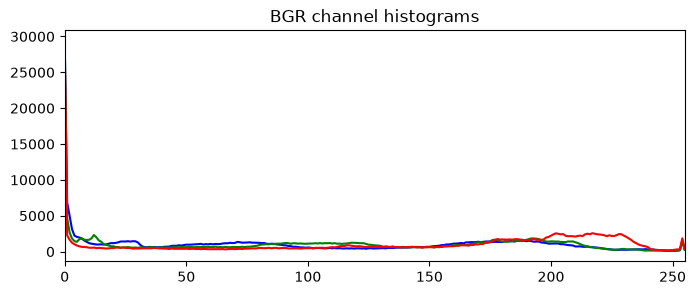

In [14]:
hist_gray=cv2.calcHist([gray],[0],None,[256],[0,256])
plt.figure(figsize=(8,3)); plt.plot(hist_gray); plt.xlim(0,255)
plt.title("Grayscale histogram");plt.xlabel("Intensity");plt.ylabel("Pixels");plt.show()
plt.figure(figsize=(8,3))
for i,c in enumerate(("b","g","r")):
    plt.plot(cv2.calcHist([img],[i],None,[256],[0,256]),color=c)
plt.xlim(0,255);plt.title("BGR channel histograms");plt.show()

## 12. Thresholding and Otsu's Automatic Threshold

Thresholding converts a grayscale image to two levels. A fixed threshold is chosen manually, while Otsu's method estimates a threshold from the intensity distribution. A histogram with two separated peaks can make threshold selection easier.

Otsu threshold: 102.0


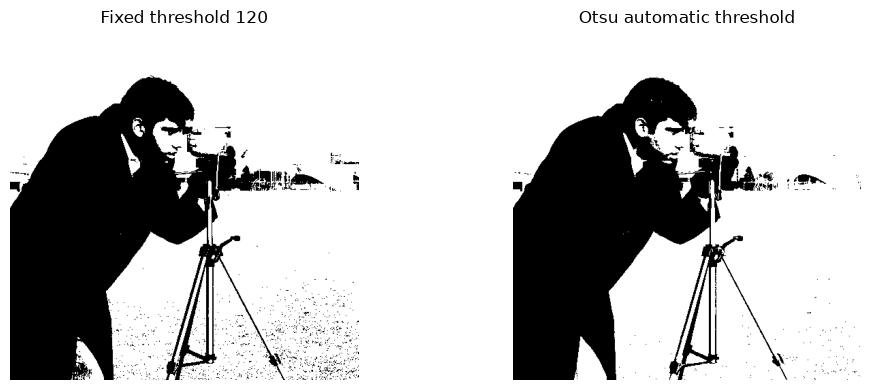

In [15]:
_,binary=cv2.threshold(camera,120,255,cv2.THRESH_BINARY)
otsu_value,otsu=cv2.threshold(camera,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
print("Otsu threshold:",otsu_value)
pair(binary,otsu,("Fixed threshold 120","Otsu automatic threshold"))

## 13. Histogram Equalization

`cv2.equalizeHist()` remaps grayscale intensities using the cumulative histogram to often improve global contrast. It does not guarantee a perfectly uniform histogram and may amplify noise.

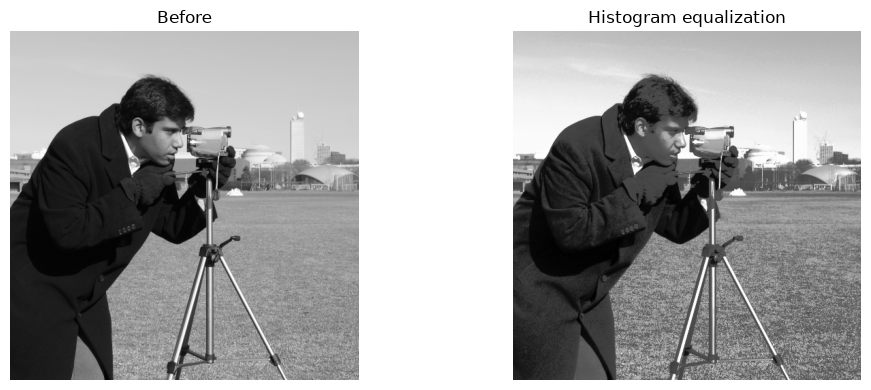

C:\Users\Surface Laptop\AppData\Local\Temp\ipykernel_27968\2178092073.py:4: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(camera.ravel(),256,[0,256],alpha=.5,label="Before")
C:\Users\Surface Laptop\AppData\Local\Temp\ipykernel_27968\2178092073.py:5: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(equalized.ravel(),256,[0,256],alpha=.5,label="After")


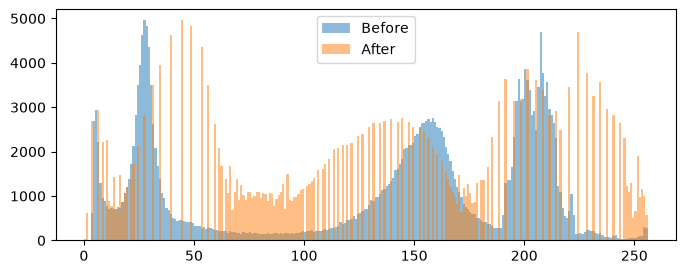

In [16]:
equalized=cv2.equalizeHist(camera)
pair(camera,equalized,("Before","Histogram equalization"))
plt.figure(figsize=(8,3))
plt.hist(camera.ravel(),256,[0,256],alpha=.5,label="Before")
plt.hist(equalized.ravel(),256,[0,256],alpha=.5,label="After")
plt.legend();plt.show()

## 14. Adjust Brightness and Contrast with a Linear Transform

Use `output = clip(alpha * input + beta, 0, 255)`. The multiplier `alpha` changes intensity differences; the offset `beta` shifts brightness. Clipping can remove highlight or shadow detail.

Note: `cv2.convertScaleAbs()` also applies an absolute value, so it differs from simple clipping when intermediate values are negative.

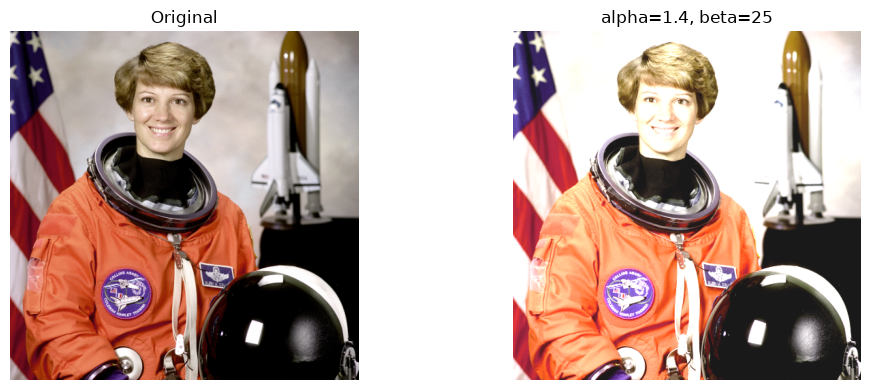

In [17]:
alpha,beta=1.4,25
linear=np.clip(img.astype(np.float32)*alpha+beta,0,255).astype(np.uint8)
pair(img,linear,("Original",f"alpha={alpha}, beta={beta}"))
# Note: cv2.convertScaleAbs uses abs() before clipping, which matters for negative beta.

## 15. Gamma Correction

Gamma correction uses a nonlinear power transform: `output = 255 * (input / 255) ** gamma`. Under this convention, gamma below 1 brightens midtones and shadows; gamma above 1 darkens them. A lookup table (LUT) makes the transformation efficient.

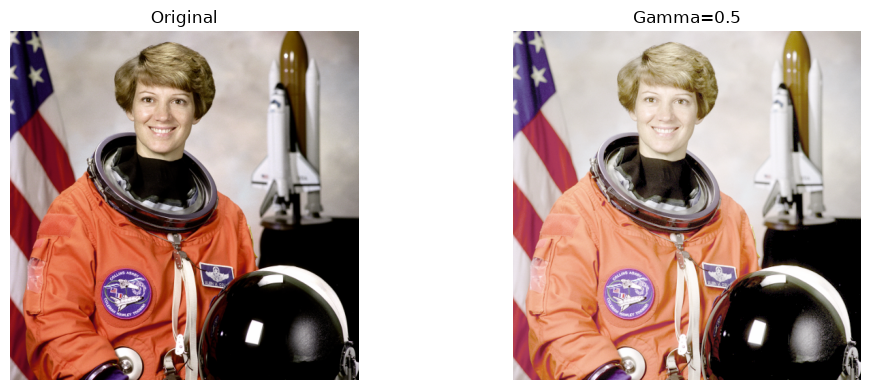

In [18]:
gamma=0.5
lut=np.array([np.clip(255*(i/255)**gamma,0,255) for i in range(256)],dtype=np.uint8)
corrected=cv2.LUT(img,lut)
pair(img,corrected,("Original",f"Gamma={gamma}"))

## 16. Practice Exercises

1. Create an HSV color mask for an object in `chelsea.png`.
2. Draw two circular masks and combine them with OR.
3. Apply two different gamma values to `camera.png` and compare their histograms.
4. Add an English label to each processed image using `putText`, then save the result in `outputs/`.

**Challenge:** Try replacing one of the sample images with a photograph of your own and observe how the results change.